# 04. Machine Learning Modeling & Benchmarking

การประเมินประสิทธิภาพโมเดล Machine Learning แบบ **Time-Based Train-Test Split (80/20)** บนตัวแปรเป้าหมาย 6 ชุด (`Import_Avg`, `Export_Avg`, `BH_Pct`, `BDMS_Pct`, `EGCO_Pct`, `BCP_Pct`) โดยแบ่งการทดลองออกเป็น 2 ส่วนอย่างเป็นอิสระต่อกัน:
- **Part 1 (Baseline Pipeline):** ใช้ 5 ฟีเจอร์ตั้งต้นจาก `data/03_processed/baseline_pipeline_data.csv`
- **Part 2 (Engineered Features Pipeline):** ใช้ฟีเจอร์หลังทำ Feature Engineering (28 ฟีเจอร์, 5-Day Horizon) จาก `data/03_processed/final_pipeline_data.csv`

## Part 1: Baseline Modeling Pipeline (5 ฟีเจอร์ตั้งต้น)

### 1.1 Load Baseline Dataset (โหลดชุดข้อมูลตั้งต้นจาก Step 03)
- โหลดชุดข้อมูลตั้งต้นที่ผ่านการจัดเตรียมและ Alignment เรียบร้อยแล้วจาก `data/03_processed/baseline_pipeline_data.csv` (สร้างจากขั้นตอน `03_feature_engineering.ipynb`)
- แกนฟีเจอร์ตั้งต้น (X — 5 ตัว): `Brent`, `US_10Y`, `USD_THB`, `Volatility_to_Open`, `Yield_Curve_Slope`
- ตัวแปรเป้าหมาย (Y — 6 ตัว): `Import_Avg`, `Export_Avg`, `BH_Pct`, `BDMS_Pct`, `EGCO_Pct`, `BCP_Pct`

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from IPython.display import display


def configure_thai_font(style=None):
    """ตั้งค่าธีม (ถ้ามี) และลงทะเบียนฟอนต์ภาษาไทย Sarabun อย่างปลอดภัย"""
    if style:
        sns.set_theme(style=style)
    font_candidates = [
        Path("./Sarabun-Regular.ttf"),
        Path("../notebooks/Sarabun-Regular.ttf"),
        Path("notebooks/Sarabun-Regular.ttf"),
    ]
    font_path = next((p for p in font_candidates if p.exists()), None)
    if font_path is not None:
        fm.fontManager.addfont(str(font_path))
        font_prop = fm.FontProperties(fname=str(font_path))
        plt.rcParams["font.family"] = font_prop.get_name()
    else:
        font_prop = fm.FontProperties()
    plt.rcParams["axes.unicode_minus"] = False
    return font_prop


# โหลดข้อมูล Baseline จาก data/03_processed/baseline_pipeline_data.csv
baseline_candidates = [
    Path("../data/03_processed/baseline_pipeline_data.csv"),
    Path("data/03_processed/baseline_pipeline_data.csv"),
    Path("./baseline_pipeline_data.csv"),
]
baseline_csv_path = next((p for p in baseline_candidates if p.exists()), None)
if baseline_csv_path is None:
    raise FileNotFoundError(
        "ไม่พบไฟล์ baseline_pipeline_data.csv กรุณารัน 03_feature_engineering.ipynb เพื่อสร้างไฟล์ก่อน"
    )

df_baseline = pd.read_csv(baseline_csv_path)
df_baseline["Date"] = pd.to_datetime(df_baseline["Date"])

x_cols_base = ["Brent", "US_10Y", "USD_THB", "Volatility_to_Open", "Yield_Curve_Slope"]
y_cols_base = ["Import_Avg", "Export_Avg", "BH_Pct", "BDMS_Pct", "EGCO_Pct", "BCP_Pct"]

missing_cols = [c for c in ["Date"] + x_cols_base + y_cols_base if c not in df_baseline.columns]
if missing_cols:
    raise KeyError(f"ไม่พบคอลัมน์ที่จำเป็นใน baseline_pipeline_data.csv: {missing_cols}")

X_base = df_baseline[x_cols_base].copy()
Y_base = df_baseline[y_cols_base].copy()

print(f"✓ โหลด baseline_pipeline_data.csv สำเร็จจาก: {baseline_csv_path}")
print(f"  ขนาดข้อมูล: {df_baseline.shape[0]} แถว x {df_baseline.shape[1]} คอลัมน์")
display(df_baseline.head(5))

✓ โหลด baseline_pipeline_data.csv สำเร็จจาก: ../data/03_processed/baseline_pipeline_data.csv
  ขนาดข้อมูล: 2813 แถว x 12 คอลัมน์


,Date,Brent,US_10Y,USD_THB,Volatility_to_Open,Yield_Curve_Slope,Import_Avg,Export_Avg,BH_Pct,BDMS_Pct,EGCO_Pct,BCP_Pct
0,2016-01-02,0.000000,0.000000,-0.012623,0.027083,0.570,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,2016-01-03,0.075058,-0.063077,-0.000281,0.025646,0.670,0.018859,0.047636,-0.030973,-0.009132,0.003003,-0.111312
2,2016-01-04,0.050530,-0.029009,-0.011664,0.028904,0.475,0.070221,0.078025,-0.050228,0.082949,0.059880,0.043557
3,2016-01-06,0.285751,0.036640,0.014930,0.030110,0.410,0.047656,-0.028907,-0.072115,0.017021,0.022599,-0.237457
4,2016-01-07,0.012671,-0.208265,-0.016531,0.048536,0.410,-0.314804,-0.028907,-0.072115,0.017021,0.022599,-0.314804


### 1.2 Temporal Train-Test Split (Baseline 80/20)
- จัดเรียงข้อมูลตามมิติเวลา (Chronological order) จากอดีตไปปัจจุบันเพื่อป้องกัน Data Leakage
- แบ่งชุดข้อมูลเป็น Train Set 80% และ Test Set 20% โดยไม่มีการสุ่มสลับ (No Shuffle)

In [2]:
# 1. เรียงลำดับข้อมูลตามวันที่จากอดีตไปปัจจุบัน
df_baseline_sorted = df_baseline.sort_values(by="Date").reset_index(drop=True)

dates_base = df_baseline_sorted["Date"]
X_base_sorted = df_baseline_sorted[x_cols_base]
Y_base_sorted = df_baseline_sorted[y_cols_base]

# 2. คำนวณจุดตัดแบ่งข้อมูล (Temporal Cutoff) ที่ 80%
split_ratio_base = 0.8
split_idx_base = int(len(df_baseline_sorted) * split_ratio_base)

# 3. แบ่ง Train / Test โดยคงลำดับเวลา
X_train_base = X_base_sorted.iloc[:split_idx_base].reset_index(drop=True)
X_test_base = X_base_sorted.iloc[split_idx_base:].reset_index(drop=True)
Y_train_base = Y_base_sorted.iloc[:split_idx_base].reset_index(drop=True)
Y_test_base = Y_base_sorted.iloc[split_idx_base:].reset_index(drop=True)
train_dates_base = dates_base.iloc[:split_idx_base].reset_index(drop=True)
test_dates_base = dates_base.iloc[split_idx_base:].reset_index(drop=True)

print("=== [สรุปผลการทำ Temporal Train-Test Split (Baseline 80:20)] ===\n")
print(f"จำนวนข้อมูลทั้งหมด: {len(df_baseline_sorted)} วัน")
print(f"ชุดข้อมูลฝึกสอน (Train Set): {X_train_base.shape[0]} วัน ({split_ratio_base * 100:.1f}%)")
print(f"  - วันเริ่มต้น: {train_dates_base.min().strftime('%Y-%m-%d')} ถึง วันสิ้นสุด: {train_dates_base.max().strftime('%Y-%m-%d')}")
print(f"ชุดข้อมูลทดสอบ (Test Set): {X_test_base.shape[0]} วัน ({(1 - split_ratio_base) * 100:.1f}%)")
print(f"  - วันเริ่มต้น: {test_dates_base.min().strftime('%Y-%m-%d')} ถึง วันสิ้นสุด: {test_dates_base.max().strftime('%Y-%m-%d')}")
print(f"\nขนาด X_train_base: {X_train_base.shape} | ขนาด Y_train_base: {Y_train_base.shape}")
print(f"ขนาด X_test_base:  {X_test_base.shape}  | ขนาด Y_test_base:  {Y_test_base.shape}")

=== [สรุปผลการทำ Temporal Train-Test Split (Baseline 80:20)] ===

จำนวนข้อมูลทั้งหมด: 2813 วัน
ชุดข้อมูลฝึกสอน (Train Set): 2250 วัน (80.0%)
  - วันเริ่มต้น: 2016-01-02 ถึง วันสิ้นสุด: 2024-08-19
ชุดข้อมูลทดสอบ (Test Set): 563 วัน (20.0%)
  - วันเริ่มต้น: 2024-08-20 ถึง วันสิ้นสุด: 2026-12-10

ขนาด X_train_base: (2250, 5) | ขนาด Y_train_base: (2250, 6)
ขนาด X_test_base:  (563, 5)  | ขนาด Y_test_base:  (563, 6)


### 1.3 Preprocessing Pipeline (StandardScaler — Baseline)
- สร้าง Scikit-Learn `Pipeline` โดยใช้ `StandardScaler` เพื่อปรับสเกลฟีเจอร์แกน X
- Fit เฉพาะบน `X_train_base` เท่านั้น แล้วนำไป Transform บน `X_test_base` เพื่อป้องกัน Data Leakage

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. สร้าง Preprocessing Pipeline
preprocessing_pipeline_base = Pipeline([
    ("scaler", StandardScaler()),
])

# 2. Fit เฉพาะบนชุด Train เพื่อป้องกัน Data Leakage
X_train_base_scaled = pd.DataFrame(
    preprocessing_pipeline_base.fit_transform(X_train_base),
    columns=x_cols_base,
)
X_test_base_scaled = pd.DataFrame(
    preprocessing_pipeline_base.transform(X_test_base),
    columns=x_cols_base,
)

# 3. ตรวจสอบสถิติก่อนและหลังปรับสเกล
comparison_summary_base = pd.DataFrame({
    "Mean (Before Scaled)": X_train_base.mean(),
    "Std (Before Scaled)": X_train_base.std(),
    "Mean (After Scaled)": X_train_base_scaled.mean(),
    "Std (After Scaled)": X_train_base_scaled.std(),
})

print("=== [สรุปการทำ Feature Scaling ด้วย StandardScaler บน X_train_base] ===\n")
display(comparison_summary_base)
print("\nตัวอย่างข้อมูล X_train_base_scaled (5 แถวแรก):")
display(X_train_base_scaled.head(5))
print(f"ขนาด X_train_base_scaled: {X_train_base_scaled.shape} | X_test_base_scaled: {X_test_base_scaled.shape}")

=== [สรุปการทำ Feature Scaling ด้วย StandardScaler บน X_train_base] ===



,Mean (Before Scaled),Std (Before Scaled),Mean (After Scaled),Std (After Scaled)
Brent,0.002947,0.088950,-2.368476e-18,1.000222
US_10Y,0.002100,0.099574,-6.315935e-18,1.000222
USD_THB,0.000183,0.020094,9.473903e-18,1.000222
Volatility_to_Open,0.027858,0.010785,-3.221127e-16,1.000222
Yield_Curve_Slope,0.587847,0.188561,6.568573e-16,1.000222



ตัวอย่างข้อมูล X_train_base_scaled (5 แถวแรก):


,Brent,US_10Y,USD_THB,Volatility_to_Open,Yield_Curve_Slope
0,-0.033141,-0.021090,-0.637443,-0.071862,-0.094668
1,0.810872,-0.654697,-0.023075,-0.205093,0.435784
2,0.535054,-0.312488,-0.589693,0.097083,-0.598597
3,3.180061,0.346962,0.734078,0.208892,-0.943390
4,0.109341,-2.113112,-0.831982,1.917637,-0.943390


ขนาด X_train_base_scaled: (2250, 5) | X_test_base_scaled: (563, 5)


### 1.4 Model Training & Baseline Classification Evaluation (1-Day Direction)
- แปลงตัวแปรเป้าหมายเป็น Binary Classification (`1` เมื่อ Return > 0 และ `0` เมื่อ Return <= 0)
- เทรนและเปรียบเทียบโมเดล Classification (`Majority Class Baseline`, `Logistic Regression`, `Random Forest`, `Gradient Boosting`)
- วัดประสิทธิภาพด้วย `Accuracy`, `Precision`, `Recall`, `F1-Score`, และ `ROC-AUC` สำหรับเป้าหมายทั้ง 6 ตัว

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. แปลงเป้าหมายเป็น Binary Classification (1 เมื่อ Return > 0, 0 เมื่อ <= 0)
Y_train_base_class = Y_train_base.apply(lambda col: np.where(col > 0, 1, 0))
Y_test_base_class = Y_test_base.apply(lambda col: np.where(col > 0, 1, 0))

baseline_1d_results = []

# 2. เทรนและประเมินผลแยกตามแต่ละตัวแปรเป้าหมาย
for col in Y_train_base_class.columns:
    y_tr = Y_train_base_class[col]
    y_te = Y_test_base_class[col]

    # --- A. Majority Class Baseline ---
    majority_class = y_tr.mode()[0]
    baseline_preds = np.full(shape=len(y_te), fill_value=majority_class)
    baseline_1d_results.append({
        "Target": col,
        "Model": "Baseline (Majority Class)",
        "Accuracy": accuracy_score(y_te, baseline_preds),
        "Precision": precision_score(y_te, baseline_preds, zero_division=0),
        "Recall": recall_score(y_te, baseline_preds, zero_division=0),
        "F1-Score": f1_score(y_te, baseline_preds, zero_division=0),
        "ROC-AUC": 0.5,
    })

    # --- B. Machine Learning Classifiers (สร้างอินสแตนซ์ใหม่ทุกรอบของ target) ---
    clfs_base = {
        "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
        "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    }

    for model_name, clf in clfs_base.items():
        clf.fit(X_train_base_scaled, y_tr)
        preds = clf.predict(X_test_base_scaled)
        probs = clf.predict_proba(X_test_base_scaled)[:, 1] if hasattr(clf, "predict_proba") else preds

        baseline_1d_results.append({
            "Target": col,
            "Model": model_name,
            "Accuracy": accuracy_score(y_te, preds),
            "Precision": precision_score(y_te, preds, zero_division=0),
            "Recall": recall_score(y_te, preds, zero_division=0),
            "F1-Score": f1_score(y_te, preds, zero_division=0),
            "ROC-AUC": roc_auc_score(y_te, probs),
        })

df_baseline_1d_summary = pd.DataFrame(baseline_1d_results)

print("=== [ตารางสรุปผลโมเดล Classification (Baseline 5 ฟีเจอร์ - 1-Day Direction)] ===")
for target in Y_train_base_class.columns:
    print(f"\nTarget: {target}")
    df_sub = df_baseline_1d_summary[df_baseline_1d_summary["Target"] == target].copy()
    display(df_sub.sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True))

=== [ตารางสรุปผลโมเดล Classification (Baseline 5 ฟีเจอร์ - 1-Day Direction)] ===

Target: Import_Avg


,Target,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Import_Avg,Logistic Regression,0.557726,0.569930,0.564014,0.566957,0.575215
1,Import_Avg,Random Forest,0.522202,0.537594,0.494810,0.515315,0.548443
2,Import_Avg,Gradient Boosting,0.523979,0.542857,0.460208,0.498127,0.545418
3,Import_Avg,Baseline (Majority Class),0.513321,0.513321,1.000000,0.678404,0.500000



Target: Export_Avg


,Target,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Export_Avg,Logistic Regression,0.547069,0.552752,0.800664,0.654003,0.597969
1,Export_Avg,Baseline (Majority Class),0.534636,0.534636,1.000000,0.696759,0.500000
2,Export_Avg,Random Forest,0.483126,0.517986,0.478405,0.497409,0.499791
3,Export_Avg,Gradient Boosting,0.488455,0.519878,0.564784,0.541401,0.473599



Target: BH_Pct


,Target,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,BH_Pct,Random Forest,0.566607,0.551724,0.422642,0.478632,0.582557
1,BH_Pct,Gradient Boosting,0.550622,0.540000,0.305660,0.390361,0.565797
2,BH_Pct,Logistic Regression,0.527531,0.495575,0.211321,0.296296,0.520780
3,BH_Pct,Baseline (Majority Class),0.529307,0.000000,0.000000,0.000000,0.500000


... (2 outputs left out)


Target: EGCO_Pct


,Target,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,EGCO_Pct,Random Forest,0.547069,0.459821,0.434599,0.446855,0.536583
1,EGCO_Pct,Logistic Regression,0.566607,0.464646,0.194093,0.273810,0.519751
2,EGCO_Pct,Baseline (Majority Class),0.579041,0.000000,0.000000,0.000000,0.500000
3,EGCO_Pct,Gradient Boosting,0.522202,0.411111,0.312236,0.354916,0.499476



Target: BCP_Pct


,Target,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,BCP_Pct,Logistic Regression,0.509769,0.727273,0.304985,0.429752,0.579100
1,BCP_Pct,Random Forest,0.502664,0.624490,0.448680,0.522184,0.501513
2,BCP_Pct,Baseline (Majority Class),0.394316,0.000000,0.000000,0.000000,0.500000
3,BCP_Pct,Gradient Boosting,0.470693,0.578182,0.466276,0.516234,0.468112


### 1.5 Visualizing Baseline Predictions (Actual vs. Predicted & Confusion Matrix)
- แสดงกราฟเปรียบเทียบทิศทางจริง (Actual) กับค่าทำนาย (Predicted) ในช่วง 60 วันล่าสุดของ Test Set สำหรับ `Import_Avg` และ `Export_Avg`
- แสดง Confusion Matrix เพื่อดูการกระจายของ True Positive / False Positive

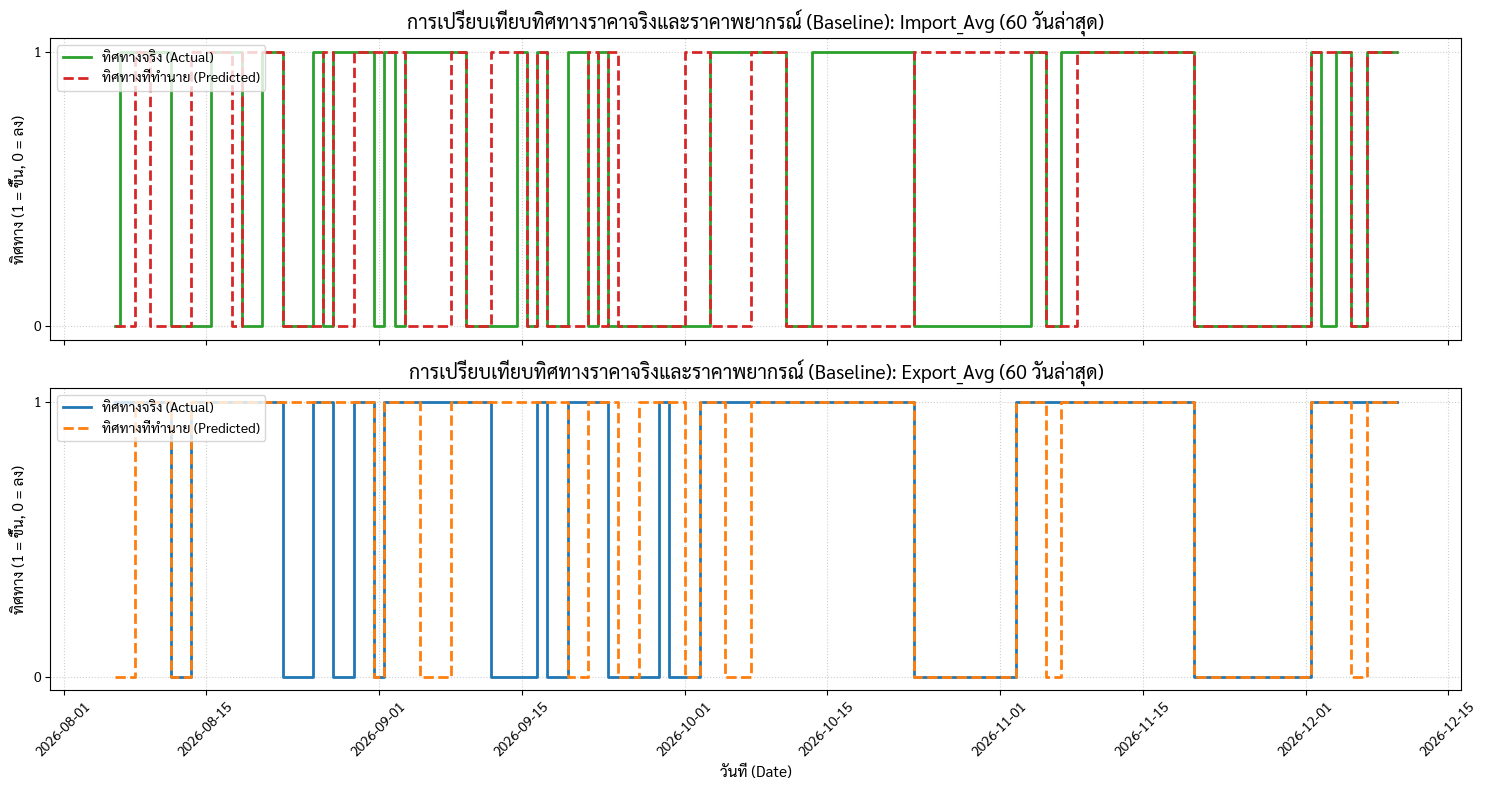

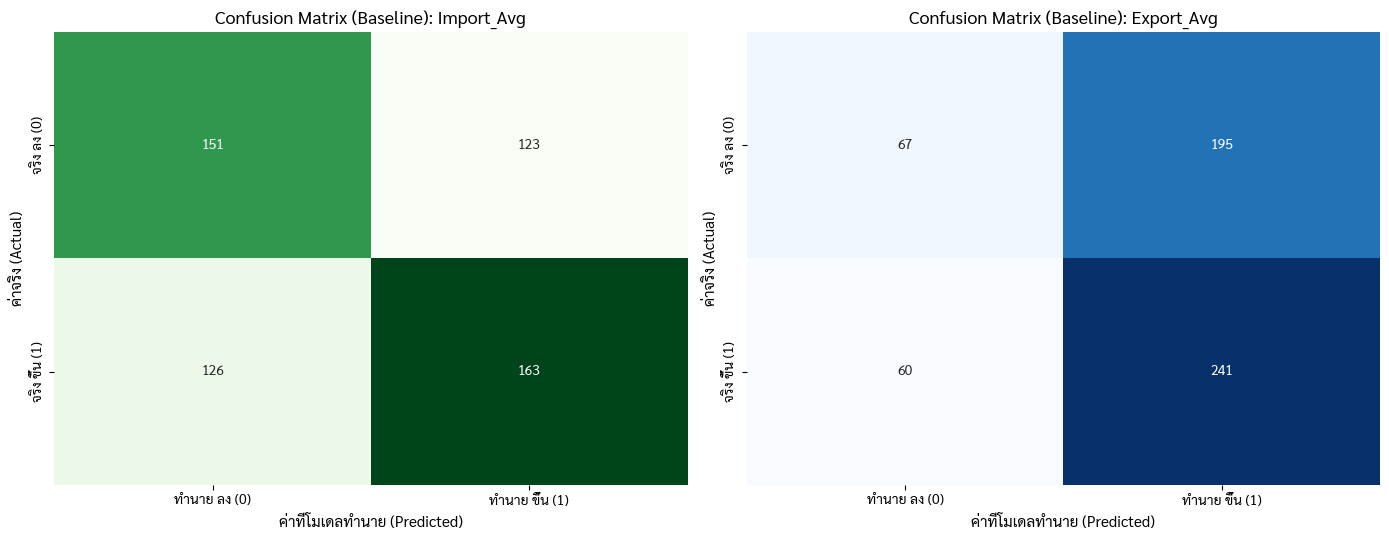

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

thai_font = configure_thai_font()

# เทรน Logistic Regression สำหรับดัชนีเฉลี่ยกลุ่มนำเข้าและส่งออก
model_import_base = LogisticRegression(random_state=42, max_iter=1000)
model_export_base = LogisticRegression(random_state=42, max_iter=1000)

model_import_base.fit(X_train_base_scaled, Y_train_base_class["Import_Avg"])
model_export_base.fit(X_train_base_scaled, Y_train_base_class["Export_Avg"])

preds_import_base = model_import_base.predict(X_test_base_scaled)
preds_export_base = model_export_base.predict(X_test_base_scaled)

actual_import_base = Y_test_base_class["Import_Avg"].values
actual_export_base = Y_test_base_class["Export_Avg"].values

# ดึง 60 วันล่าสุดของ Test Set สำหรับพล็อตกราฟอนุกรมเวลา
plot_df_base = (
    pd.DataFrame({
        "Date": test_dates_base,
        "Actual_Import": actual_import_base,
        "Pred_Import": preds_import_base,
        "Actual_Export": actual_export_base,
        "Pred_Export": preds_export_base,
    })
    .sort_values("Date")
    .tail(60)
    .reset_index(drop=True)
)

# 1. กราฟ Step Chart เปรียบเทียบทิศทางจริง vs ทำนาย
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

ax1.step(plot_df_base["Date"], plot_df_base["Actual_Import"], where="mid", label="ทิศทางจริง (Actual)", color="#2ca02c", linewidth=2)
ax1.step(plot_df_base["Date"], plot_df_base["Pred_Import"], where="mid", label="ทิศทางที่ทำนาย (Predicted)", color="#d62728", linestyle="--", linewidth=2)
ax1.set_title("การเปรียบเทียบทิศทางราคาจริงและราคาพยากรณ์ (Baseline): Import_Avg (60 วันล่าสุด)", fontproperties=thai_font, fontsize=14, fontweight="bold")
ax1.set_ylabel("ทิศทาง (1 = ขึ้น, 0 = ลง)", fontproperties=thai_font, fontsize=11)
ax1.set_yticks([0, 1])
ax1.legend(prop=thai_font, loc="upper left")
ax1.grid(True, linestyle=":", alpha=0.6)

ax2.step(plot_df_base["Date"], plot_df_base["Actual_Export"], where="mid", label="ทิศทางจริง (Actual)", color="#1f77b4", linewidth=2)
ax2.step(plot_df_base["Date"], plot_df_base["Pred_Export"], where="mid", label="ทิศทางที่ทำนาย (Predicted)", color="#ff7f0e", linestyle="--", linewidth=2)
ax2.set_title("การเปรียบเทียบทิศทางราคาจริงและราคาพยากรณ์ (Baseline): Export_Avg (60 วันล่าสุด)", fontproperties=thai_font, fontsize=14, fontweight="bold")
ax2.set_xlabel("วันที่ (Date)", fontproperties=thai_font, fontsize=11)
ax2.set_ylabel("ทิศทาง (1 = ขึ้น, 0 = ลง)", fontproperties=thai_font, fontsize=11)
ax2.set_yticks([0, 1])
ax2.legend(prop=thai_font, loc="upper left")
ax2.grid(True, linestyle=":", alpha=0.6)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. กราฟ Confusion Matrix
cm_import_base = confusion_matrix(actual_import_base, preds_import_base)
cm_export_base = confusion_matrix(actual_export_base, preds_export_base)

fig_cm, (ax_cm1, ax_cm2) = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(
    cm_import_base, annot=True, fmt="d", cmap="Greens", ax=ax_cm1, cbar=False,
    xticklabels=["ทำนาย ลง (0)", "ทำนาย ขึ้น (1)"],
    yticklabels=["จริง ลง (0)", "จริง ขึ้น (1)"],
)
ax_cm1.set_title("Confusion Matrix (Baseline): Import_Avg", fontproperties=thai_font, fontsize=13, fontweight="bold")
ax_cm1.set_xlabel("ค่าที่โมเดลทำนาย (Predicted)", fontproperties=thai_font, fontsize=11)
ax_cm1.set_ylabel("ค่าจริง (Actual)", fontproperties=thai_font, fontsize=11)
for label in ax_cm1.get_xticklabels() + ax_cm1.get_yticklabels():
    label.set_fontproperties(thai_font)

sns.heatmap(
    cm_export_base, annot=True, fmt="d", cmap="Blues", ax=ax_cm2, cbar=False,
    xticklabels=["ทำนาย ลง (0)", "ทำนาย ขึ้น (1)"],
    yticklabels=["จริง ลง (0)", "จริง ขึ้น (1)"],
)
ax_cm2.set_title("Confusion Matrix (Baseline): Export_Avg", fontproperties=thai_font, fontsize=13, fontweight="bold")
ax_cm2.set_xlabel("ค่าที่โมเดลทำนาย (Predicted)", fontproperties=thai_font, fontsize=11)
ax_cm2.set_ylabel("ค่าจริง (Actual)", fontproperties=thai_font, fontsize=11)
for label in ax_cm2.get_xticklabels() + ax_cm2.get_yticklabels():
    label.set_fontproperties(thai_font)

plt.tight_layout()
plt.show()

### 1.6 Baseline 5-Day Horizon Evaluation & Feature Importance (5 ฟีเจอร์ตั้งต้น)
- ประเมินประสิทธิภาพของ 5 ฟีเจอร์ตั้งต้นในการทำนายทิศทางผลตอบแทนสะสม **5 วันข้างหน้า** (`rolling(5).sum().shift(-5)`)
- วิเคราะห์สัมประสิทธิ์อิทธิพล (Logistic Regression Coefficients) เปรียบเทียบระหว่างพอร์ตเฉลี่ยและหุ้นรายตัว

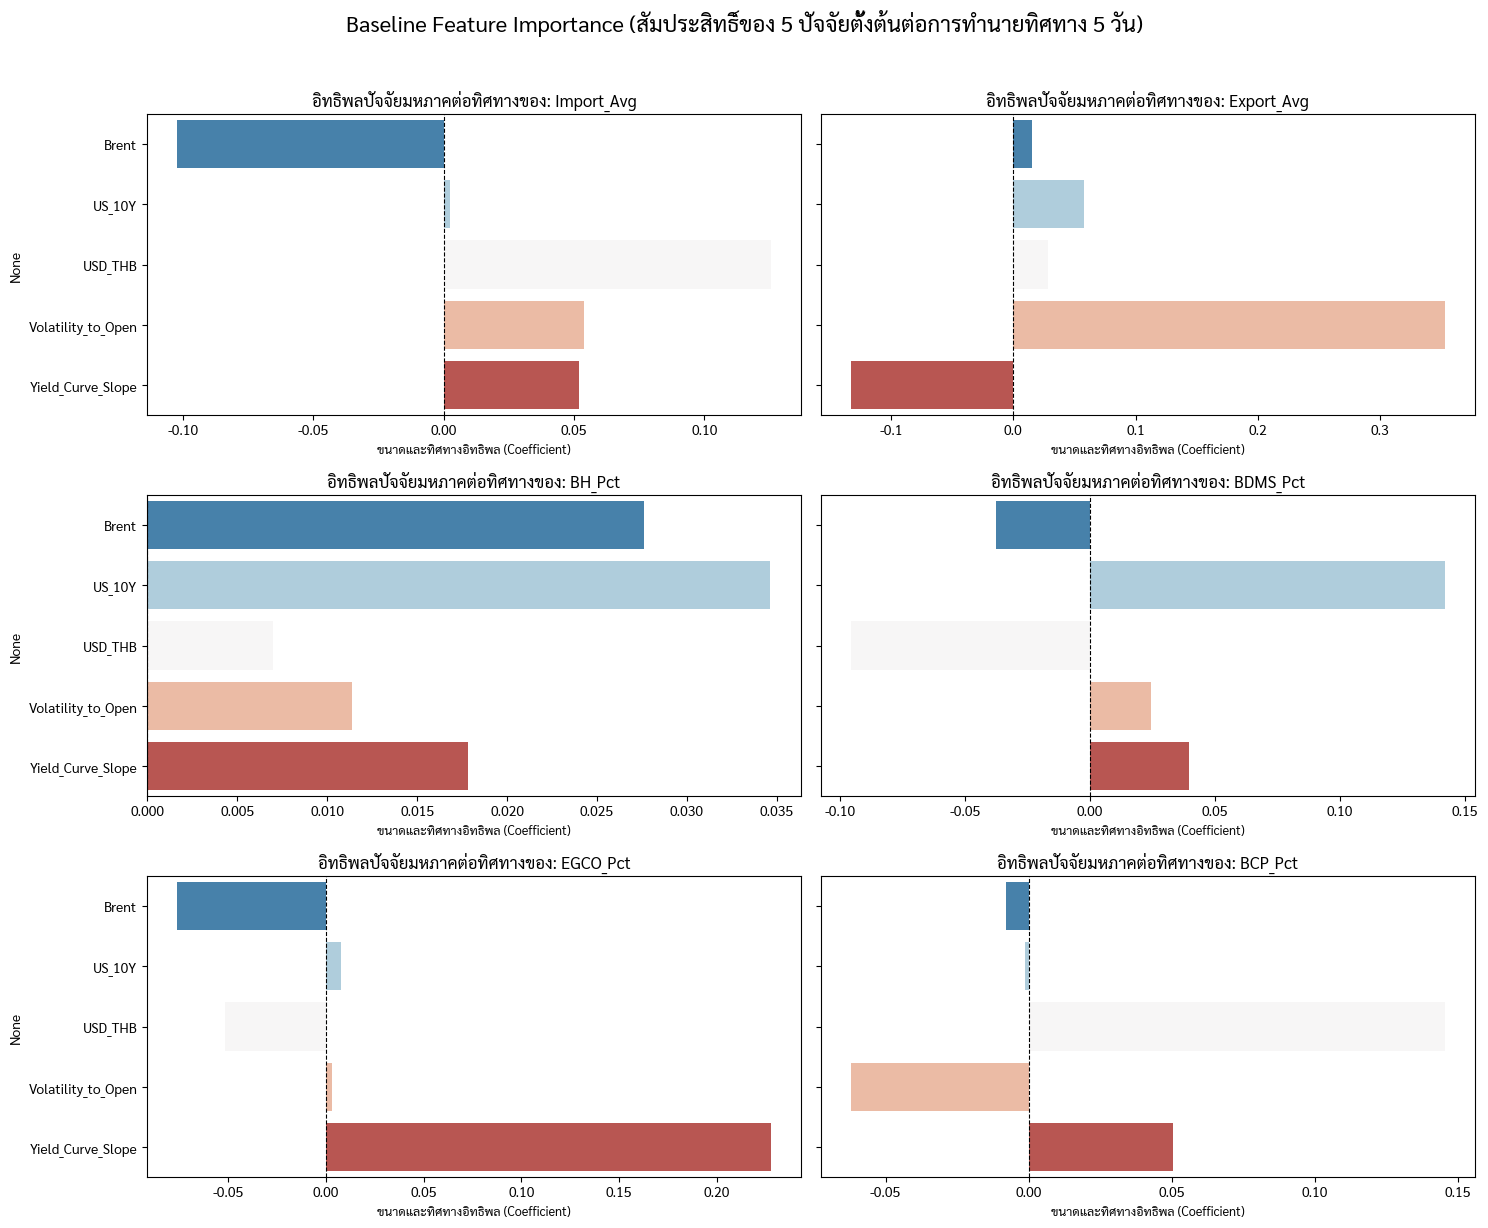


=== [ตารางสรุปประสิทธิภาพ Baseline 5-Day Direction (พอร์ตเฉลี่ย VS หุ้นรายตัว)] ===


,Target,Type,Accuracy (5-Day Direction),F1-Score,ROC-AUC
0,Import_Avg,พอร์ตเฉลี่ย (Portfolio Index),0.551971,0.677835,0.544072
1,EGCO_Pct,หุ้นรายตัว (Single Stock),0.517921,0.590563,0.533739
2,BH_Pct,หุ้นรายตัว (Single Stock),0.500000,0.665868,0.525712
3,BDMS_Pct,หุ้นรายตัว (Single Stock),0.473118,0.632500,0.486616
4,Export_Avg,พอร์ตเฉลี่ย (Portfolio Index),0.521505,0.650980,0.477956
5,BCP_Pct,หุ้นรายตัว (Single Stock),0.474910,0.488656,0.451692


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

thai_font = configure_thai_font()

# สร้างเป้าหมายทิศทาง 5 วันข้างหน้าจากผลตอบแทนต่อเนื่อง (คำนวณแยกภายใน Train และ Test เพื่อป้องกัน Leakage ข้ามรอยต่อ)
Y_train_5d_base = Y_train_base.rolling(window=5).sum().shift(-5)
Y_test_5d_base = Y_test_base.rolling(window=5).sum().shift(-5)

train_mask_5d = Y_train_5d_base.notna().all(axis=1)
test_mask_5d = Y_test_5d_base.notna().all(axis=1)

X_train_5d_clean = X_train_base_scaled.loc[train_mask_5d]
X_test_5d_clean = X_test_base_scaled.loc[test_mask_5d]

Y_train_class_5d_base = Y_train_5d_base.loc[train_mask_5d].apply(lambda col: np.where(col > 0, 1, 0))
Y_test_class_5d_base = Y_test_5d_base.loc[test_mask_5d].apply(lambda col: np.where(col > 0, 1, 0))

coef_data_base = {}
baseline_5d_results = []

for col in y_cols_base:
    model_5d = LogisticRegression(random_state=42, max_iter=1000)
    model_5d.fit(X_train_5d_clean, Y_train_class_5d_base[col])

    coef_data_base[col] = model_5d.coef_[0]
    preds_5d = model_5d.predict(X_test_5d_clean)
    probs_5d = model_5d.predict_proba(X_test_5d_clean)[:, 1]

    baseline_5d_results.append({
        "Target": col,
        "Type": "พอร์ตเฉลี่ย (Portfolio Index)" if "Avg" in col else "หุ้นรายตัว (Single Stock)",
        "Accuracy (5-Day Direction)": accuracy_score(Y_test_class_5d_base[col], preds_5d),
        "F1-Score": f1_score(Y_test_class_5d_base[col], preds_5d, zero_division=0),
        "ROC-AUC": roc_auc_score(Y_test_class_5d_base[col], probs_5d),
    })

df_baseline_5d_perf = pd.DataFrame(baseline_5d_results)
df_coefs_base = pd.DataFrame(coef_data_base, index=x_cols_base)

# พล็อต Feature Importance (Coefficients)
fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharey=True)
axes = axes.flatten()

for idx, col in enumerate(y_cols_base):
    importance = df_coefs_base[col]
    sns.barplot(
        x=importance.values,
        y=importance.index,
        ax=axes[idx],
        palette="RdBu_r",
        hue=importance.index,
        legend=False,
    )
    axes[idx].set_title(f"อิทธิพลปัจจัยมหภาคต่อทิศทางของ: {col}", fontproperties=thai_font, fontsize=12, fontweight="bold")
    axes[idx].axvline(0, color="black", linestyle="--", linewidth=0.8)
    axes[idx].set_xlabel("ขนาดและทิศทางอิทธิพล (Coefficient)", fontproperties=thai_font, fontsize=9)
    for tick in axes[idx].get_yticklabels():
        tick.set_fontproperties(thai_font)

fig.suptitle(
    "Baseline Feature Importance (สัมประสิทธิ์ของ 5 ปัจจัยตั้งต้นต่อการทำนายทิศทาง 5 วัน)",
    fontproperties=thai_font,
    fontsize=16,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

print("\n=== [ตารางสรุปประสิทธิภาพ Baseline 5-Day Direction (พอร์ตเฉลี่ย VS หุ้นรายตัว)] ===")
display(df_baseline_5d_perf.sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True))

### 1.7 Baseline Summary (บทสรุปวิเคราะห์เชิงโครงสร้างรอบ Baseline)

#### **1) ประสิทธิภาพเชิงโครงสร้าง (Portfolio vs. Single Stock)**
* **พอร์ตเฉลี่ย (`Import_Avg` & `Export_Avg`) มีสัญญาณที่เป็นระบบกว่าหุ้นรายตัว:**
  ราคาหุ้นรายตัวมีความเสี่ยงเฉพาะตัว (Idiosyncratic Risk) และ Noise สูง (เช่น ข่าวผลประกอบการ สภาพคล่อง และการเก็งกำไรรายวัน) ในขณะที่การถัวเฉลี่ยเป็นพอร์ตโฟลิโอช่วยลดสัญญาณรบกวนเฉพาะตัวลง ทำให้แบบจำลองจับความสัมพันธ์กับปัจจัยมหภาคได้ชัดเจนกว่า

#### **2) อิทธิพลของ 5 ปัจจัยมหภาคตั้งต้น**
* **พอร์ตนำเข้า (`Import_Avg`):** อ่อนไหวเชิงลบต่อค่าเงินบาทอ่อนค่า (`USD_THB` สูงขึ้นทำให้ต้นทุนนำเข้าเพิ่มขึ้น) และสัมพันธ์กับความชันเส้นอัตราผลตอบแทนพันธบัตรไทย (`Yield_Curve_Slope`)
* **พอร์ตส่งออก (`Export_Avg`):** ได้รับแรงหนุนจาก `USD_THB` และความผันผวนของตลาดภาพรวม (`Volatility_to_Open`)
* **ราคาน้ำมันเบรนท์ (`Brent`):** ส่งผลชัดเจนต่อหุ้นพลังงานและโรงกลั่นรายตัว (เช่น `BCP`) มากกว่าภาพรวมพอร์ตอื่น

---
## Part 2: Modeling After Feature Engineering (28 ฟีเจอร์, 5-Day Horizon)

### 2.1 Load Final Engineered Dataset & Time-Based Train-Test Split (80/20)
- โหลดชุดข้อมูลหลังทำ Feature Engineering สมบูรณ์จาก `data/03_processed/final_pipeline_data.csv` (สร้างจากขั้นตอน `03_feature_engineering.ipynb`)
- แบ่งข้อมูลแบบ Chronological 80/20 โดยแยก Namespace ตัวแปร (`*_fe`) ออกจาก Part 1 อย่างชัดเจน เพื่อให้สามารถรัน Part 2 แยกเดี่ยวหรือรันทั้ง Notebook ซ้ำได้อย่างปลอดภัย

In [7]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display

# 1. โหลด final_pipeline_data.csv ใหม่ทุกครั้ง (เป็นอิสระจาก Part 1)
fe_candidates = [
    Path("../data/03_processed/final_pipeline_data.csv"),
    Path("data/03_processed/final_pipeline_data.csv"),
    Path("./final_pipeline_data.csv"),
]
fe_csv_path = next((p for p in fe_candidates if p.exists()), None)
if fe_csv_path is None:
    raise FileNotFoundError(
        "ไม่พบไฟล์ final_pipeline_data.csv กรุณารัน 03_feature_engineering.ipynb เพื่อสร้างไฟล์ก่อน"
    )

df_final_dataset = pd.read_csv(fe_csv_path)
df_final_dataset["Date"] = pd.to_datetime(df_final_dataset["Date"])
df_final_dataset = df_final_dataset.sort_values(by="Date").reset_index(drop=True)

y_cols_fe = ["Import_Avg", "Export_Avg", "BH_Pct", "BDMS_Pct", "EGCO_Pct", "BCP_Pct"]
missing_fe_targets = [c for c in y_cols_fe if c not in df_final_dataset.columns]
if missing_fe_targets:
    raise KeyError(f"ไม่พบคอลัมน์เป้าหมายใน final_pipeline_data.csv: {missing_fe_targets}")

x_cols_fe = [c for c in df_final_dataset.columns if c not in ["Date"] + y_cols_fe]
dates_fe = df_final_dataset["Date"]
X_fe = df_final_dataset[x_cols_fe].copy()
Y_fe_raw = df_final_dataset[y_cols_fe].copy()
Y_fe_class = Y_fe_raw.apply(lambda col: np.where(col > 0, 1, 0))

print(f"✓ โหลด final_pipeline_data.csv สำเร็จจาก: {fe_csv_path} ({X_fe.shape[1]} ฟีเจอร์)")

# 2. แบ่ง Train / Test แบบอิงลำดับเวลา (80/20, No Shuffle)
split_ratio_fe = 0.8
split_idx_fe = int(len(df_final_dataset) * split_ratio_fe)

X_train_fe = X_fe.iloc[:split_idx_fe].reset_index(drop=True)
X_test_fe = X_fe.iloc[split_idx_fe:].reset_index(drop=True)
Y_train_fe = Y_fe_class.iloc[:split_idx_fe].reset_index(drop=True)
Y_test_fe = Y_fe_class.iloc[split_idx_fe:].reset_index(drop=True)
train_dates_fe = dates_fe.iloc[:split_idx_fe].reset_index(drop=True)
test_dates_fe = dates_fe.iloc[split_idx_fe:].reset_index(drop=True)

# 3. ตรวจสอบการทับซ้อนของเวลาและคุณภาพข้อมูล
print("\n=== [สรุปโครงสร้างข้อมูลหลังการแบ่ง Time-Based Split (After FE)] ===")
print(f"จำนวนวันทำงานรวมทั้งหมด: {len(df_final_dataset)} วัน")
print(f"ชุดฝึกสอน (Train Set): {len(X_train_fe)} วัน ({split_ratio_fe * 100:.1f}%)")
print(f"  - ตั้งแต่ {train_dates_fe.min().strftime('%Y-%m-%d')} ถึง {train_dates_fe.max().strftime('%Y-%m-%d')}")
print(f"ชุดทดสอบ (Test Set)  : {len(X_test_fe)} วัน ({(1 - split_ratio_fe) * 100:.1f}%)")
print(f"  - ตั้งแต่ {test_dates_fe.min().strftime('%Y-%m-%d')} ถึง {test_dates_fe.max().strftime('%Y-%m-%d')}")

overlap_fe = set(train_dates_fe).intersection(set(test_dates_fe))
print(
    f"✓ ไม่พบการทับซ้อนของข้อมูลชุด Train และ Test (Overlap = {len(overlap_fe)} วัน)"
    if len(overlap_fe) == 0
    else f"⚠ ตรวจพบข้อมูลทับซ้อนจำนวน: {len(overlap_fe)} วัน"
)
print(f"✓ การเรียงลำดับเวลาถูกต้อง (Max Train Date < Min Test Date): {train_dates_fe.max() < test_dates_fe.min()}")

nans_train = X_train_fe.isna().sum().sum()
nans_test = X_test_fe.isna().sum().sum()
infs_train = np.isinf(X_train_fe.select_dtypes(include=[np.number])).sum().sum()
infs_test = np.isinf(X_test_fe.select_dtypes(include=[np.number])).sum().sum()
print(f"✓ ตรวจสอบค่าว่าง (NaN): Train={nans_train} ค่า | Test={nans_test} ค่า")
print(f"✓ ตรวจสอบค่าอนันต์ (Inf): Train={infs_train} ค่า | Test={infs_test} ค่า\n")

# 4. สรุปสัดส่วนคลาสของเป้าหมาย Y ทั้ง 6 ตัว
print("=== [ตารางสัดส่วนคลาสของตัวแปรเป้าหมาย (Class Distribution)] ===")
class_ratios_fe = []
for col in Y_train_fe.columns:
    train_dist = Y_train_fe[col].value_counts(normalize=True).to_dict()
    test_dist = Y_test_fe[col].value_counts(normalize=True).to_dict()
    class_ratios_fe.append({
        "Target Variable": col,
        "Train Class 1 (Up)": f"{train_dist.get(1, 0.0):.2%}",
        "Train Class 0 (Down/Flat)": f"{train_dist.get(0, 0.0):.2%}",
        "Test Class 1 (Up)": f"{test_dist.get(1, 0.0):.2%}",
        "Test Class 0 (Down/Flat)": f"{test_dist.get(0, 0.0):.2%}",
    })
display(pd.DataFrame(class_ratios_fe))

✓ โหลด final_pipeline_data.csv สำเร็จจาก: ../data/03_processed/final_pipeline_data.csv (28 ฟีเจอร์)

=== [สรุปโครงสร้างข้อมูลหลังการแบ่ง Time-Based Split (After FE)] ===
จำนวนวันทำงานรวมทั้งหมด: 2788 วัน
ชุดฝึกสอน (Train Set): 2230 วัน (80.0%)
  - ตั้งแต่ 2016-01-28 ถึง 2024-08-19
ชุดทดสอบ (Test Set)  : 558 วัน (20.0%)
  - ตั้งแต่ 2024-08-20 ถึง 2026-12-02
✓ ไม่พบการทับซ้อนของข้อมูลชุด Train และ Test (Overlap = 0 วัน)
✓ การเรียงลำดับเวลาถูกต้อง (Max Train Date < Min Test Date): True
✓ ตรวจสอบค่าว่าง (NaN): Train=0 ค่า | Test=0 ค่า
✓ ตรวจสอบค่าอนันต์ (Inf): Train=0 ค่า | Test=0 ค่า

=== [ตารางสัดส่วนคลาสของตัวแปรเป้าหมาย (Class Distribution)] ===


,Target Variable,Train Class 1 (Up),Train Class 0 (Down/Flat),Test Class 1 (Up),Test Class 0 (Down/Flat)
0,Import_Avg,52.24%,47.76%,56.45%,43.55%
1,Export_Avg,54.08%,45.92%,58.78%,41.22%
2,BH_Pct,53.72%,46.28%,51.08%,48.92%
3,BDMS_Pct,54.44%,45.56%,46.59%,53.41%
4,EGCO_Pct,51.70%,48.30%,54.66%,45.34%
5,BCP_Pct,49.96%,50.04%,59.68%,40.32%


### 2.2 Model Training & Benchmarking After Feature Engineering
- เทรนและเปรียบเทียบอัลกอริทึม 5 ตัว (`Logistic Regression`, `Random Forest`, `Gradient Boosting`, `XGBoost`, `LightGBM`) บนฟีเจอร์ทั้ง 28 ตัวสำหรับการทำนายทิศทางล่วงหน้า 5 วันของเป้าหมายทั้ง 6 ชุด

In [8]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, precision_score, recall_score

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None

try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None


def get_models_dict():
    """คืนค่า Dictionary ของโมเดล Classification สำหรับการเปรียบเทียบ"""
    clfs = {
        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("lr", LogisticRegression(max_iter=1000, random_state=42)),
        ]),
        "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    }
    if XGBClassifier is not None:
        clfs["XGBoost"] = XGBClassifier(random_state=42, eval_metric="logloss", n_jobs=-1)
    if LGBMClassifier is not None:
        clfs["LightGBM"] = LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)
    return clfs


print(f"โมเดลที่พร้อมใช้งาน: {list(get_models_dict().keys())}")

all_fe_evaluation_results = []
best_models_per_target = {}
features_fe_list = list(X_train_fe.columns)

for target_col in Y_train_fe.columns:
    print(f"🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: {target_col}...")
    y_train_target = Y_train_fe[target_col]
    y_test_target = Y_test_fe[target_col]

    available_models = get_models_dict()
    best_auc = -1.0
    best_model_name = None
    best_model_obj = None

    for model_name, model_obj in available_models.items():
        model_obj.fit(X_train_fe, y_train_target)

        if hasattr(model_obj, "predict_proba"):
            test_probs = model_obj.predict_proba(X_test_fe)[:, 1]
        else:
            test_probs = model_obj.predict(X_test_fe)

        auc_score = roc_auc_score(y_test_target, test_probs)
        test_preds = model_obj.predict(X_test_fe)

        all_fe_evaluation_results.append({
            "Target": target_col,
            "Model": model_name,
            "ROC-AUC": auc_score,
            "Accuracy": accuracy_score(y_test_target, test_preds),
            "F1-Score": f1_score(y_test_target, test_preds, zero_division=0),
            "Precision": precision_score(y_test_target, test_preds, zero_division=0),
            "Recall": recall_score(y_test_target, test_preds, zero_division=0),
        })

        if auc_score > best_auc:
            best_auc = auc_score
            best_model_name = model_name
            best_model_obj = model_obj

    best_models_per_target[target_col] = (best_model_name, best_model_obj)
    print(f"   🏆 โมเดลที่ดีที่สุดของ {target_col}: {best_model_name} (ROC-AUC = {best_auc:.4f})")

df_fe_eval_summary = pd.DataFrame(all_fe_evaluation_results)

โมเดลที่พร้อมใช้งาน: ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'XGBoost', 'LightGBM']
🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: Import_Avg...
   🏆 โมเดลที่ดีที่สุดของ Import_Avg: Logistic Regression (ROC-AUC = 0.6854)
🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: Export_Avg...
   🏆 โมเดลที่ดีที่สุดของ Export_Avg: Logistic Regression (ROC-AUC = 0.6342)
🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: BH_Pct...
   🏆 โมเดลที่ดีที่สุดของ BH_Pct: Logistic Regression (ROC-AUC = 0.5374)
🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: BDMS_Pct...
   🏆 โมเดลที่ดีที่สุดของ BDMS_Pct: Logistic Regression (ROC-AUC = 0.5582)
🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: EGCO_Pct...
   🏆 โมเดลที่ดีที่สุดของ EGCO_Pct: Gradient Boosting (ROC-AUC = 0.6370)
🔄 กำลังประมวลผลสำหรับตัวแปรเป้าหมาย: BCP_Pct...
   🏆 โมเดลที่ดีที่สุดของ BCP_Pct: Logistic Regression (ROC-AUC = 0.6013)


In [9]:
from IPython.display import display

print("=== [ตารางสรุปผลประสิทธิภาพโมเดลจำแนกตามเป้าหมาย (เรียงตาม ROC-AUC สูงสุด)] ===")
for target_col in Y_train_fe.columns:
    print(f"\n📊 ตัวแปรเป้าหมาย: {target_col}")
    df_target_sub = (
        df_fe_eval_summary[df_fe_eval_summary["Target"] == target_col]
        .sort_values(by="ROC-AUC", ascending=False)
        .reset_index(drop=True)
    )
    display(df_target_sub)

=== [ตารางสรุปผลประสิทธิภาพโมเดลจำแนกตามเป้าหมาย (เรียงตาม ROC-AUC สูงสุด)] ===

📊 ตัวแปรเป้าหมาย: Import_Avg


,Target,Model,ROC-AUC,Accuracy,F1-Score,Precision,Recall
0,Import_Avg,Logistic Regression,0.685427,0.627240,0.651007,0.690391,0.615873
1,Import_Avg,Random Forest,0.618120,0.577061,0.610561,0.635739,0.587302
2,Import_Avg,XGBoost,0.618002,0.609319,0.648387,0.659016,0.638095
3,Import_Avg,LightGBM,0.617023,0.573477,0.604651,0.634146,0.577778
4,Import_Avg,Gradient Boosting,0.614057,0.577061,0.605351,0.639576,0.574603



📊 ตัวแปรเป้าหมาย: Export_Avg


,Target,Model,ROC-AUC,Accuracy,F1-Score,Precision,Recall
0,Export_Avg,Logistic Regression,0.634160,0.593190,0.677098,0.634667,0.725610
1,Export_Avg,Gradient Boosting,0.629971,0.575269,0.647845,0.631884,0.664634
2,Export_Avg,Random Forest,0.616119,0.575269,0.662873,0.621333,0.710366
3,Export_Avg,LightGBM,0.612527,0.566308,0.640950,0.624277,0.658537
4,Export_Avg,XGBoost,0.599563,0.571685,0.644874,0.628986,0.661585



📊 ตัวแปรเป้าหมาย: BH_Pct


,Target,Model,ROC-AUC,Accuracy,F1-Score,Precision,Recall
0,BH_Pct,Logistic Regression,0.537408,0.514337,0.581144,0.519337,0.659649
1,BH_Pct,Gradient Boosting,0.504543,0.512545,0.549669,0.520376,0.582456
2,BH_Pct,LightGBM,0.480098,0.489247,0.484629,0.500000,0.470175
3,BH_Pct,XGBoost,0.476435,0.478495,0.490368,0.489510,0.491228
4,BH_Pct,Random Forest,0.463717,0.478495,0.504259,0.490066,0.519298


... (2 outputs left out)


📊 ตัวแปรเป้าหมาย: EGCO_Pct


,Target,Model,ROC-AUC,Accuracy,F1-Score,Precision,Recall
0,EGCO_Pct,Gradient Boosting,0.637012,0.603943,0.634711,0.640000,0.629508
1,EGCO_Pct,Random Forest,0.634653,0.609319,0.632997,0.650519,0.616393
2,EGCO_Pct,Logistic Regression,0.633150,0.577061,0.613115,0.613115,0.613115
3,EGCO_Pct,LightGBM,0.618247,0.609319,0.641447,0.643564,0.639344
4,EGCO_Pct,XGBoost,0.591965,0.553763,0.600321,0.588050,0.613115



📊 ตัวแปรเป้าหมาย: BCP_Pct


,Target,Model,ROC-AUC,Accuracy,F1-Score,Precision,Recall
0,BCP_Pct,Logistic Regression,0.601335,0.573477,0.612378,0.669039,0.564565
1,BCP_Pct,LightGBM,0.577591,0.548387,0.577181,0.653992,0.516517
2,BCP_Pct,Gradient Boosting,0.567648,0.530466,0.560403,0.634981,0.501502
3,BCP_Pct,XGBoost,0.560988,0.553763,0.591133,0.652174,0.540541
4,BCP_Pct,Random Forest,0.551585,0.528674,0.544194,0.643443,0.471471


### 2.3 Feature Importance Analysis (Best Model per Target)
- วิเคราะห์ความสำคัญของตัวแปร (Tree Feature Importance หรือ Logistic Regression Coefficient) ของโมเดลที่ทำคะแนน ROC-AUC สูงสุดในแต่ละเป้าหมาย

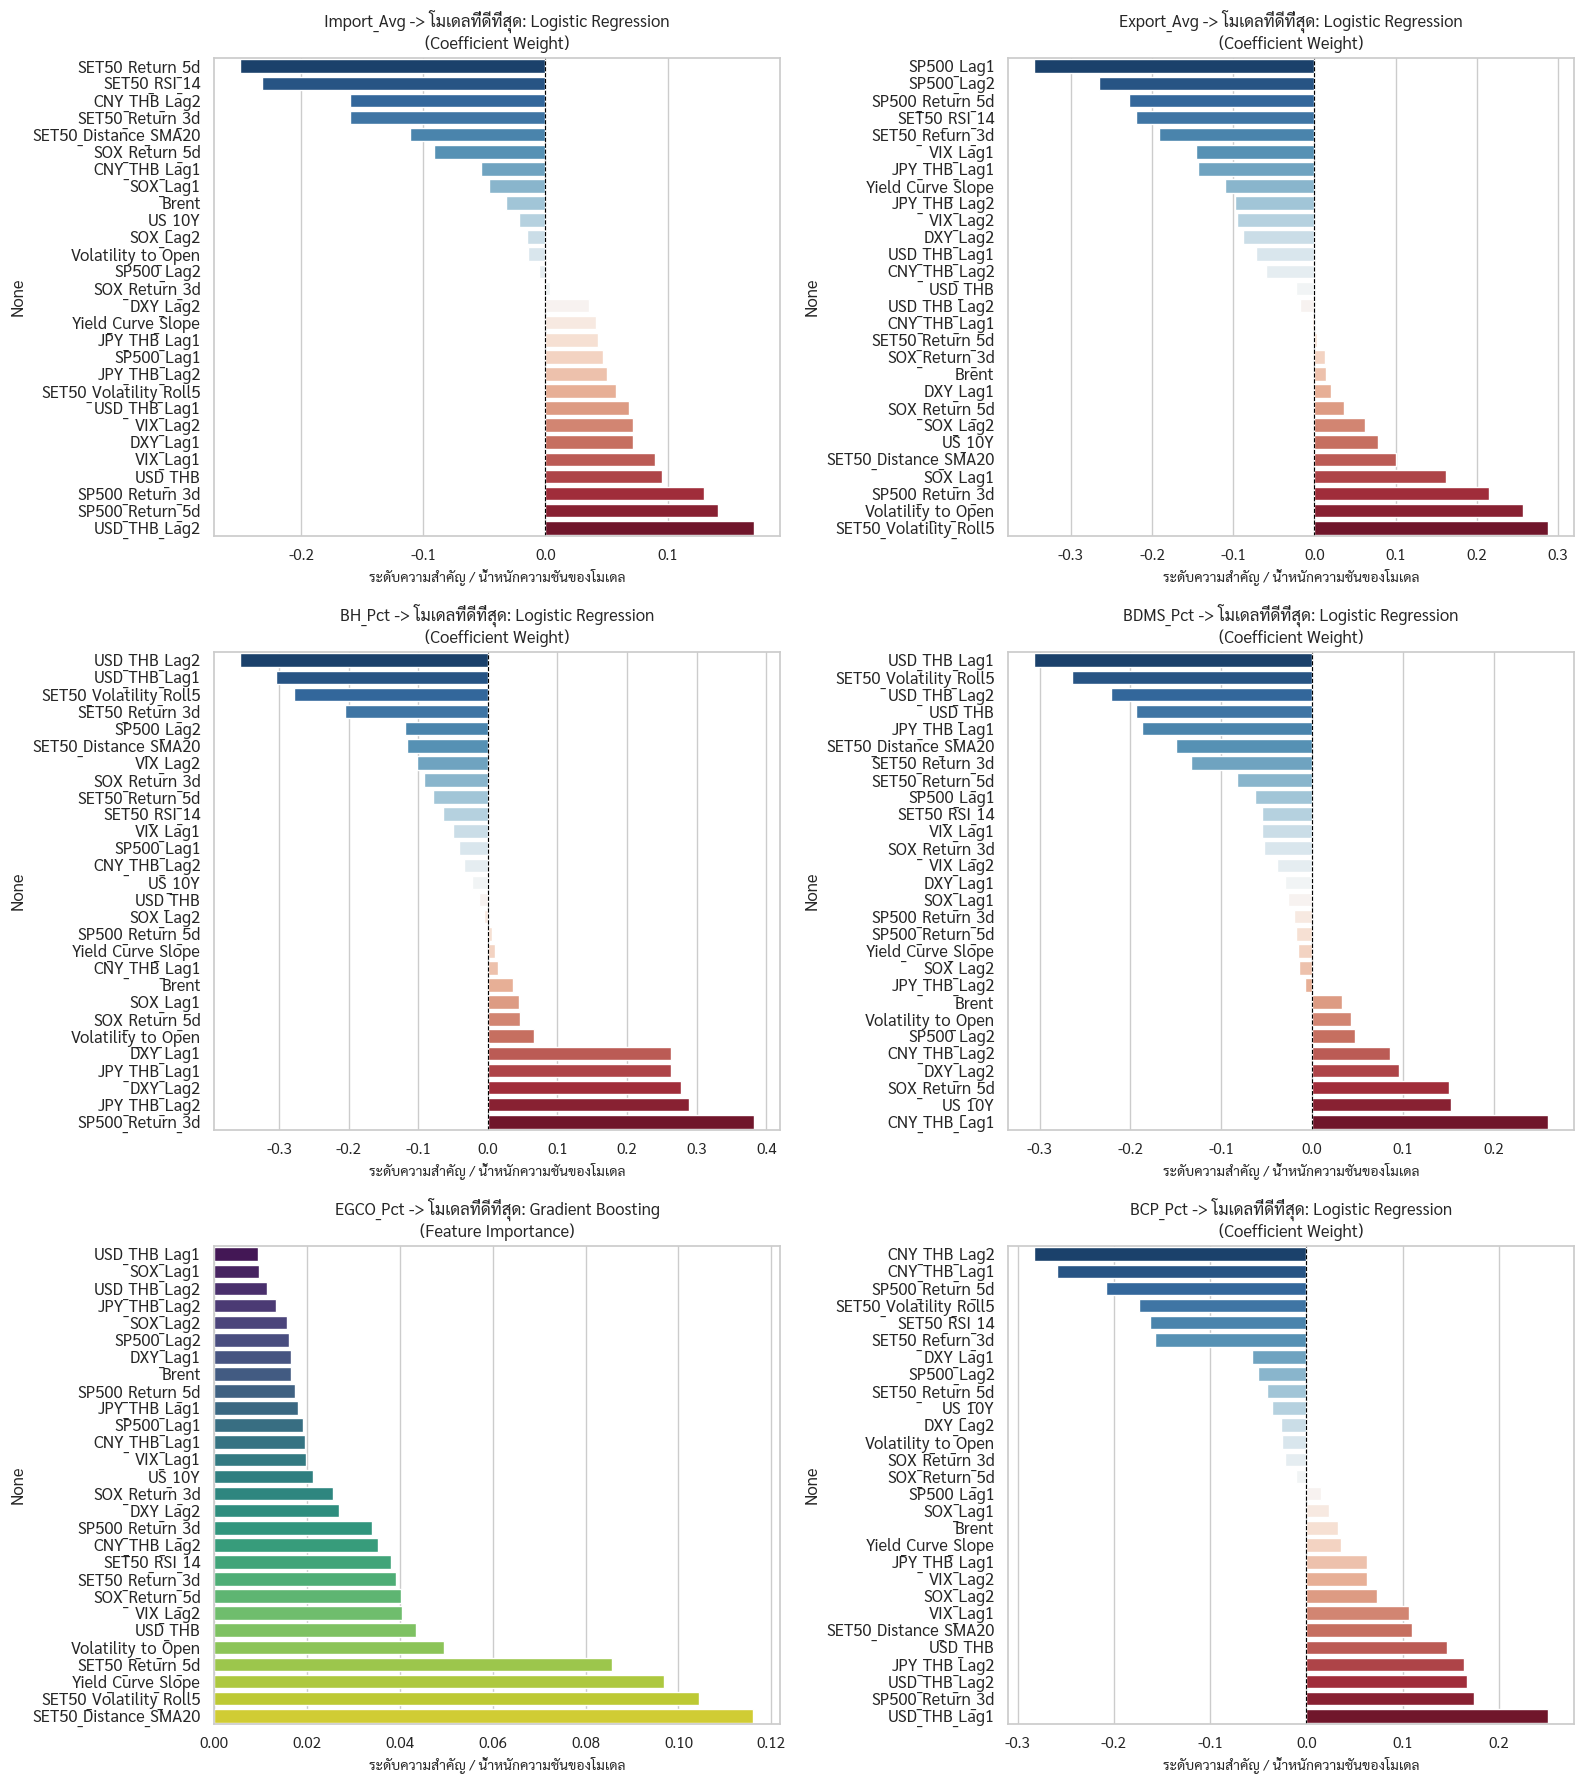

In [10]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")
font_candidates = [
    Path("./Sarabun-Regular.ttf"),
    Path("../notebooks/Sarabun-Regular.ttf"),
    Path("notebooks/Sarabun-Regular.ttf"),
]
font_path = next((p for p in font_candidates if p.exists()), None)
if font_path is not None:
    fm.fontManager.addfont(str(font_path))
    thai_font = fm.FontProperties(fname=str(font_path))
    plt.rcParams["font.family"] = thai_font.get_name()
else:
    thai_font = fm.FontProperties()
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

for idx, target_col in enumerate(Y_train_fe.columns):
    best_model_name, model_obj = best_models_per_target[target_col]
    ax = axes[idx]

    if hasattr(model_obj, "feature_importances_"):
        importance_series = pd.Series(model_obj.feature_importances_, index=features_fe_list).sort_values(ascending=True)
        sns.barplot(
            x=importance_series.values,
            y=importance_series.index,
            ax=ax,
            palette="viridis",
            hue=importance_series.index,
            legend=False,
        )
        ax.set_title(
            f"{target_col} -> โมเดลที่ดีที่สุด: {best_model_name}\n(Feature Importance)",
            fontproperties=thai_font,
            fontsize=12,
            fontweight="bold",
        )
    elif isinstance(model_obj, Pipeline) and "lr" in model_obj.named_steps and hasattr(model_obj.named_steps["lr"], "coef_"):
        coef_series = pd.Series(model_obj.named_steps["lr"].coef_[0], index=features_fe_list).sort_values(ascending=True)
        sns.barplot(
            x=coef_series.values,
            y=coef_series.index,
            ax=ax,
            palette="RdBu_r",
            hue=coef_series.index,
            legend=False,
        )
        ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
        ax.set_title(
            f"{target_col} -> โมเดลที่ดีที่สุด: {best_model_name}\n(Coefficient Weight)",
            fontproperties=thai_font,
            fontsize=12,
            fontweight="bold",
        )
    else:
        ax.text(
            0.5, 0.5, "ไม่สามารถดึงข้อมูล Feature Importance ได้",
            horizontalalignment="center", verticalalignment="center",
            fontproperties=thai_font, fontsize=12,
        )
        ax.set_title(f"{target_col} -> {best_model_name}", fontproperties=thai_font, fontsize=12, fontweight="bold")

    ax.set_xlabel("ระดับความสำคัญ / น้ำหนักความชันของโมเดล", fontproperties=thai_font, fontsize=10)
    for tick in ax.get_yticklabels():
        tick.set_fontproperties(thai_font)

plt.tight_layout()
plt.show()

### 2.4 Before vs. After Feature Engineering Comparison (ROC-AUC)
- เปรียบเทียบค่า **ROC-AUC** แบบควบคุมตัวแปรชุดข้อมูลและช่วงเวลาเดียวกัน (`X_train_fe` / `X_test_fe`, `Y_train_fe` / `Y_test_fe`, 5-Day Horizon)
- **Before FE:** ประเมินจาก 5 ฟีเจอร์ตั้งต้น (`Brent`, `US_10Y`, `USD_THB`, `Volatility_to_Open`, `Yield_Curve_Slope`)
- **After FE:** ใช้ผลลัพธ์จริงจากฟีเจอร์ทั้งหมดหลังทำ Feature Engineering (28 ฟีเจอร์) แล้วบันทึกลง `outputs/tables/model_comparison.csv`

=== [ตารางเปรียบเทียบประสิทธิภาพ ROC-AUC: ก่อนทำ VS หลังทำ Feature Engineering (Controlled Split)] ===


,Target,Best_Model_Before,Best_Model,ROC_AUC_Before,ROC_AUC_After,Difference,% Change
0,Import_Avg,Logistic Regression,Logistic Regression,0.543001,0.685427,0.142426,26.229429
1,Export_Avg,XGBoost,Logistic Regression,0.511585,0.634160,0.122574,23.959683
2,BH_Pct,Logistic Regression,Logistic Regression,0.525159,0.537408,0.012249,2.332354
3,BDMS_Pct,Random Forest,Logistic Regression,0.510054,0.558196,0.048141,9.438498
4,EGCO_Pct,Gradient Boosting,Gradient Boosting,0.546543,0.637012,0.090468,16.552852
5,BCP_Pct,XGBoost,Logistic Regression,0.556210,0.601335,0.045125,8.112972


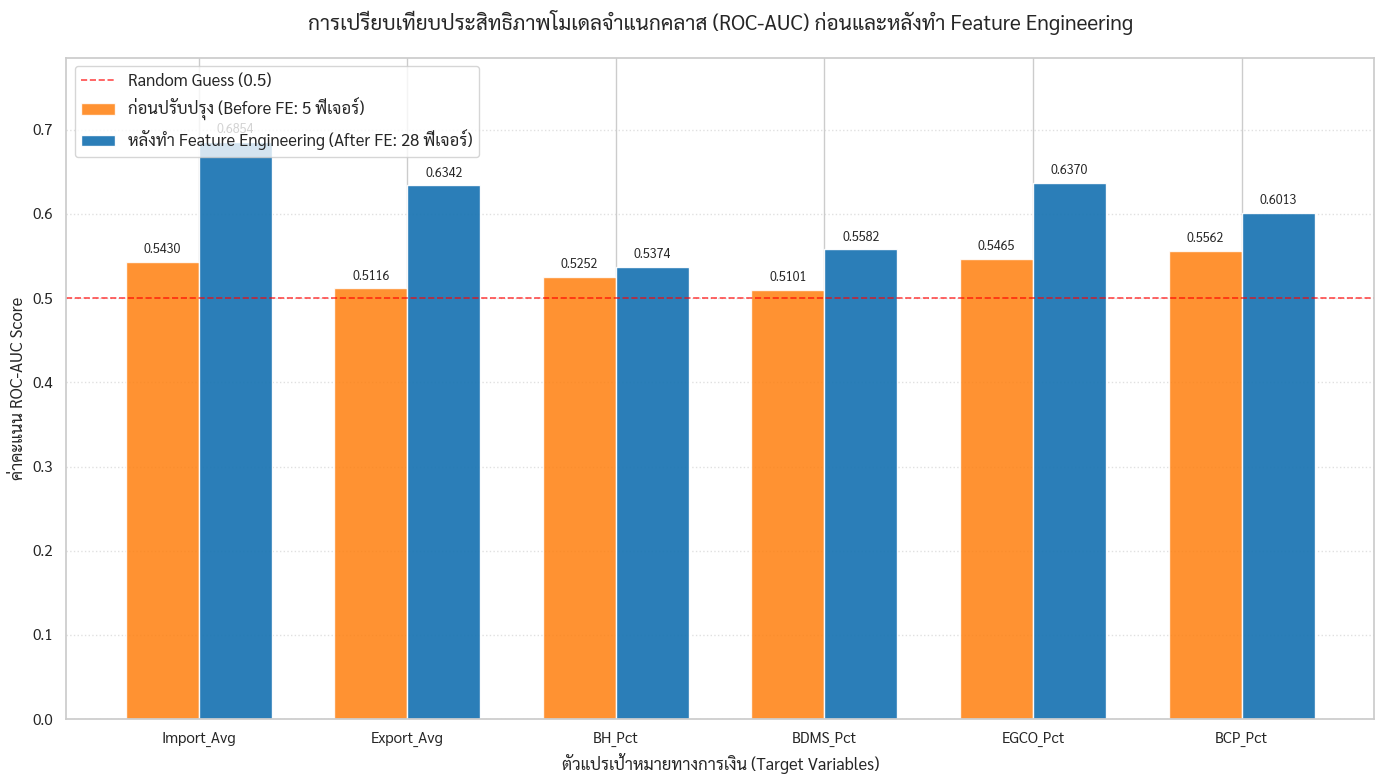


✓ บันทึกตารางเปรียบเทียบ Before vs After ลงใน: ../outputs/tables/model_comparison.csv


In [11]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from sklearn.metrics import roc_auc_score
from IPython.display import display

# 1. ประเมินชุด Baseline (5 ฟีเจอร์ตั้งต้น) บน Train/Test split เดียวกันเพื่อให้เปรียบเทียบได้อย่างเที่ยงตรง
baseline_5_cols = ["Brent", "US_10Y", "USD_THB", "Volatility_to_Open", "Yield_Curve_Slope"]
missing_base5 = [c for c in baseline_5_cols if c not in X_train_fe.columns]
if missing_base5:
    raise KeyError(f"ไม่พบฟีเจอร์ Baseline ใน X_train_fe: {missing_base5}")

X_train_b5 = X_train_fe[baseline_5_cols]
X_test_b5 = X_test_fe[baseline_5_cols]

compare_rows = []
for target_col in Y_train_fe.columns:
    y_tr = Y_train_fe[target_col]
    y_te = Y_test_fe[target_col]

    # หาโมเดลที่ดีที่สุดฝั่ง Before FE (5 ฟีเจอร์)
    best_before_auc = -1.0
    best_before_model = None
    for model_name, model_obj in get_models_dict().items():
        model_obj.fit(X_train_b5, y_tr)
        probs = model_obj.predict_proba(X_test_b5)[:, 1] if hasattr(model_obj, "predict_proba") else model_obj.predict(X_test_b5)
        auc_val = roc_auc_score(y_te, probs)
        if auc_val > best_before_auc:
            best_before_auc = auc_val
            best_before_model = model_name

    # ดึงผลโมเดลที่ดีที่สุดฝั่ง After FE (ทุกฟีเจอร์) จาก df_fe_eval_summary
    best_after_row = (
        df_fe_eval_summary[df_fe_eval_summary["Target"] == target_col]
        .sort_values(by="ROC-AUC", ascending=False)
        .iloc[0]
    )

    compare_rows.append({
        "Target": target_col,
        "Best_Model_Before": best_before_model,
        "Best_Model": best_after_row["Model"],
        "ROC_AUC_Before": best_before_auc,
        "ROC_AUC_After": float(best_after_row["ROC-AUC"]),
    })

df_compare = pd.DataFrame(compare_rows)
df_compare["Difference"] = df_compare["ROC_AUC_After"] - df_compare["ROC_AUC_Before"]
df_compare["% Change"] = (df_compare["Difference"] / df_compare["ROC_AUC_Before"]) * 100.0

print("=== [ตารางเปรียบเทียบประสิทธิภาพ ROC-AUC: ก่อนทำ VS หลังทำ Feature Engineering (Controlled Split)] ===")
display(df_compare)

# 2. ตั้งค่าฟอนต์ภาษาไทยและวาดกราฟเปรียบเทียบ Grouped Bar Chart
font_candidates = [
    Path("./Sarabun-Regular.ttf"),
    Path("../notebooks/Sarabun-Regular.ttf"),
    Path("notebooks/Sarabun-Regular.ttf"),
]
font_path = next((p for p in font_candidates if p.exists()), None)
if font_path is not None:
    fm.fontManager.addfont(str(font_path))
    thai_font = fm.FontProperties(fname=str(font_path))
    plt.rcParams["font.family"] = thai_font.get_name()
else:
    thai_font = fm.FontProperties()
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(df_compare["Target"]))
width = 0.35

rects1 = ax.bar(x - width / 2, df_compare["ROC_AUC_Before"], width, label="ก่อนปรับปรุง (Before FE: 5 ฟีเจอร์)", color="#ff7f0e", alpha=0.85)
rects2 = ax.bar(x + width / 2, df_compare["ROC_AUC_After"], width, label=f"หลังทำ Feature Engineering (After FE: {X_train_fe.shape[1]} ฟีเจอร์)", color="#1f77b4", alpha=0.95)
ax.axhline(0.5, color="red", linestyle="--", linewidth=1.2, alpha=0.7, label="Random Guess (0.5)")

max_auc_val = max(df_compare["ROC_AUC_Before"].max(), df_compare["ROC_AUC_After"].max())
ax.set_title("การเปรียบเทียบประสิทธิภาพโมเดลจำแนกคลาส (ROC-AUC) ก่อนและหลังทำ Feature Engineering", fontproperties=thai_font, fontsize=15, fontweight="bold", pad=20)
ax.set_xlabel("ตัวแปรเป้าหมายทางการเงิน (Target Variables)", fontproperties=thai_font, fontsize=12)
ax.set_ylabel("ค่าคะแนน ROC-AUC Score", fontproperties=thai_font, fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(df_compare["Target"], fontproperties=thai_font, fontsize=11)
ax.set_ylim(0.0, max(0.75, max_auc_val + 0.10))
ax.legend(prop=thai_font, loc="upper left")
ax.grid(axis="y", linestyle=":", alpha=0.6)


def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(
            f"{height:.4f}",
            xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="semibold",
        )


autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.show()

# 3. บันทึกตารางเปรียบเทียบผลลัพธ์ลง outputs/tables/model_comparison.csv
out_tab_dir = Path("../outputs/tables")
if not out_tab_dir.parent.exists():
    out_tab_dir = Path("outputs/tables")
out_tab_dir.mkdir(parents=True, exist_ok=True)
out_csv_path = out_tab_dir / "model_comparison.csv"
df_compare.to_csv(out_csv_path, index=False)
print(f"\n✓ บันทึกตารางเปรียบเทียบ Before vs After ลงใน: {out_csv_path}")